# Raster Masking Architecture: ImageAnalyzer
In this notebook, we load the High-Quality `window.png`, extract specific color masks (Red, Orange, Yellow, Green, Cyan, Blue, and Magenta), compute an ultra-heavy Gaussian blur for our "Bloom / Glow" effects, and export the resulting layers directly into our Processing sketch's `data` folder.

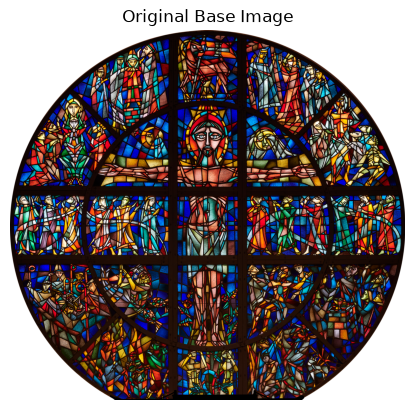

In [1]:
# Install required libraries if you don't have them
# !pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Define the output directory to point directly at the Processing sketch's data folder
output_dir = 'Visualizer/data'
os.makedirs(output_dir, exist_ok=True)

# 1. Load the original HQ PNG image without discarding its alpha channel
img_filepath = 'img/window.png'
img_bgra = cv2.imread(img_filepath, cv2.IMREAD_UNCHANGED)

if img_bgra is None:
    print(f"Error: {img_filepath} not found. Creating a mock test image to demonstrate the pipeline...")
    # Mock fallback with a transparent background
    img_bgra = np.zeros((800, 800, 4), dtype=np.uint8)
    cv2.circle(img_bgra, (400, 400), 200, (0, 255, 255, 255), -1)   # Yellow Center
    cv2.rectangle(img_bgra, (100, 100), (300, 300), (255, 0, 0, 255), -1) # Blue corner
    cv2.imwrite(img_filepath, img_bgra)
elif img_bgra.ndim == 2:
    img_bgra = cv2.cvtColor(img_bgra, cv2.COLOR_GRAY2BGRA)
elif img_bgra.shape[2] == 3:
    # Images without alpha are treated as fully opaque.
    img_bgra = cv2.cvtColor(img_bgra, cv2.COLOR_BGR2BGRA)
elif img_bgra.shape[2] != 4:
    raise ValueError(f"Unsupported image shape: {img_bgra.shape}")

# OpenCV uses BGRA. Keep alpha for export while using BGR/HSV for color analysis.
img_bgr = img_bgra[:, :, :3]
img_alpha = img_bgra[:, :, 3]
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_rgba = cv2.cvtColor(img_bgra, cv2.COLOR_BGRA2RGBA)

plt.imshow(img_rgba)
plt.title('Original Base Image')
plt.axis('off')
plt.show()

Source size: 5423 x 5070
Processing texture size: 1920 x 1795
Saved Base Image with transparency: Visualizer/data\window_base.png
Saved Solid and Bloom Masks for: red
Saved Solid and Bloom Masks for: orange
Saved Solid and Bloom Masks for: yellow
Saved Solid and Bloom Masks for: green
Saved Solid and Bloom Masks for: cyan
Saved Solid and Bloom Masks for: blue
Saved Solid and Bloom Masks for: magenta

All color extractions complete! Layers are ready for Processing.


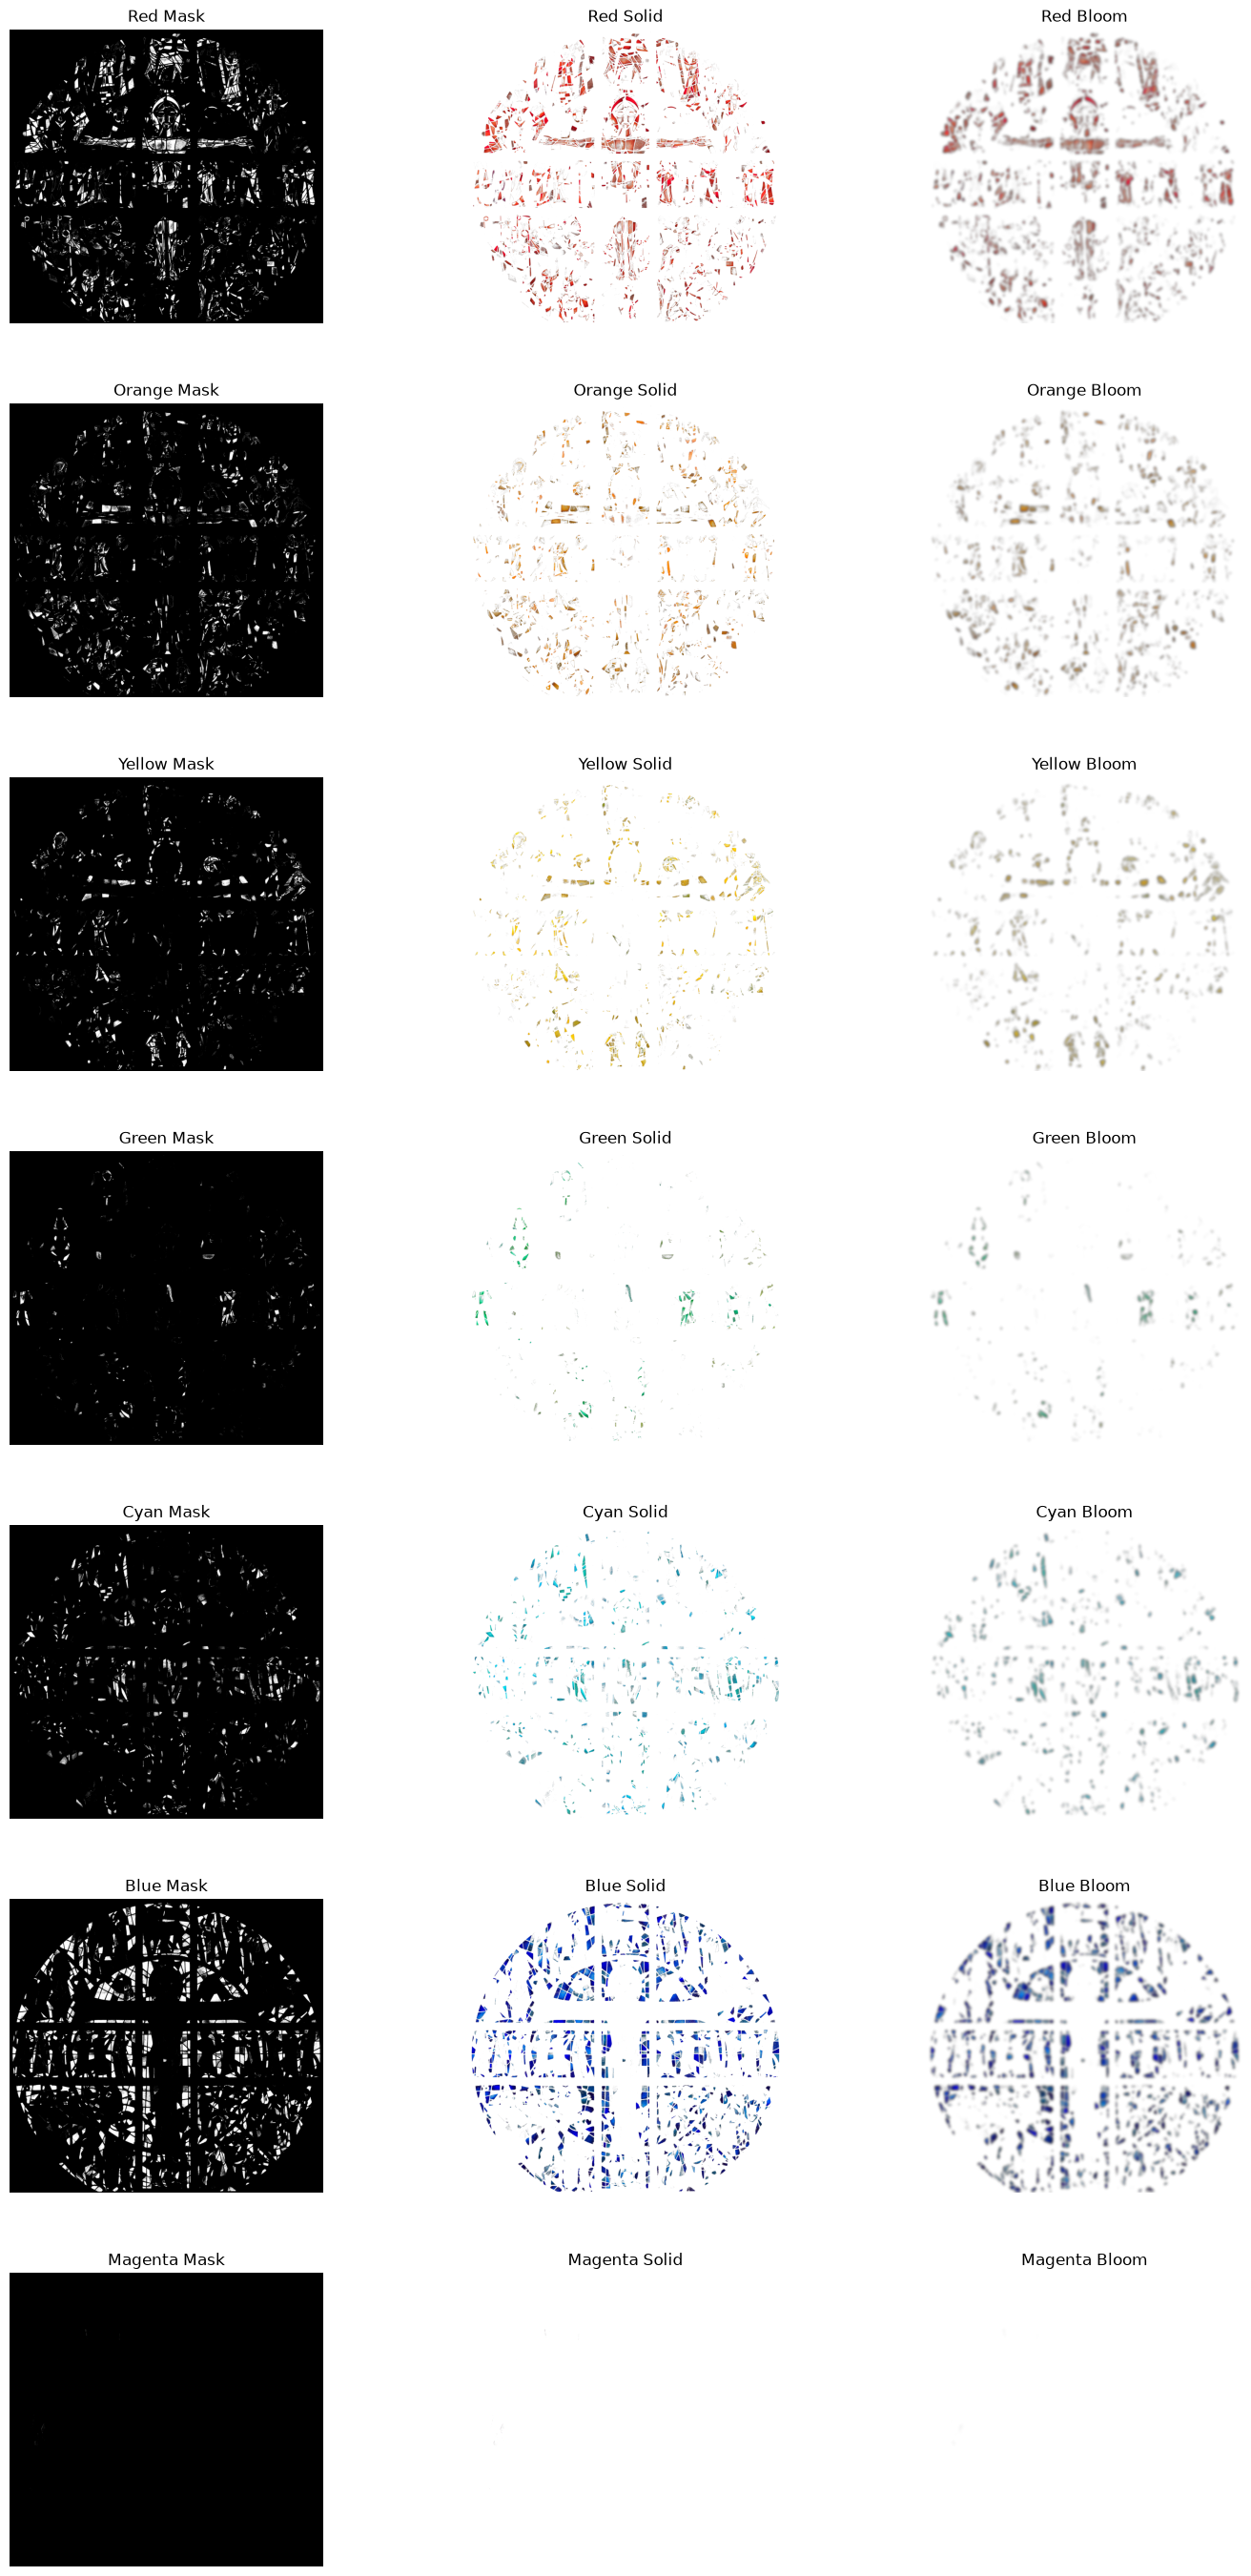

In [2]:
# 2. Define color ranges in HSV (OpenCV Hue is 0-179, Saturation 0-255, Value 0-255)
color_ranges = {
    # Red wraps around the hue circle in OpenCV (0-10 and 160-179)
    'red': [([0, 100, 100], [10, 255, 255]), ([160, 100, 100], [179, 255, 255])],
    'orange': [([10, 100, 100], [20, 255, 255])],
    'yellow': [([20, 100, 100], [35, 255, 255])],
    'green': [([35, 100, 100], [85, 255, 255])],
    'cyan': [([85, 100, 100], [100, 255, 255])],
    'blue': [([100, 100, 50], [140, 255, 255])],
    'magenta': [([140, 100, 100], [160, 255, 255])]
}

# Processing does not need the full size textures to render on a normal display.
# Keeping every source-sized mask in memory would require roughly 1.6 GB before GPU copies.
max_output_dimension = 1920
source_height, source_width = img_bgr.shape[:2]
output_scale = min(1.0, max_output_dimension / max(source_width, source_height))
output_size = (
    max(1, round(source_width * output_scale)),
    max(1, round(source_height * output_scale))
)

def resize_for_processing(image):
    """Downsample exported assets while retaining full-resolution source analysis."""
    if output_scale == 1.0:
        return image
    return cv2.resize(image, output_size, interpolation=cv2.INTER_AREA)

print(f"Source size: {source_width} x {source_height}")
print(f"Processing texture size: {output_size[0]} x {output_size[1]}")

# 3. Export a display-sized base image while preserving its alpha channel
base_out = os.path.join(output_dir, 'window_base.png')
cv2.imwrite(base_out, resize_for_processing(img_bgra))
print(f"Saved Base Image with transparency: {base_out}")

# Set up matplotlib figure to visualize the masks
num_colors = len(color_ranges)
fig, axes = plt.subplots(num_colors, 3, figsize=(15, 4 * num_colors))
fig.tight_layout(pad=4.0)

# 4. Analyze at source resolution, then export display-sized solid and bloom layers
for i, (color_name, ranges) in enumerate(color_ranges.items()):
    # Accumulate masks for multi-range colors (like Red)
    mask = np.zeros((img_hsv.shape[0], img_hsv.shape[1]), dtype=np.uint8)
    for lower, upper in ranges:
        lower_bound = np.array(lower, dtype=np.uint8)
        upper_bound = np.array(upper, dtype=np.uint8)
        mask = cv2.bitwise_or(mask, cv2.inRange(img_hsv, lower_bound, upper_bound))

    # Exclude transparent source pixels, including hidden RGB data under alpha.
    mask = cv2.bitwise_and(mask, img_alpha)

    # Create an RGBA layer containing the original pixels selected by the mask
    color_layer = np.zeros((img_rgb.shape[0], img_rgb.shape[1], 4), dtype=np.uint8)
    color_layer[mask > 0, :3] = img_rgb[mask > 0]
    color_layer[mask > 0, 3] = mask[mask > 0]

    # Blur before downsampling, retaining the high-resolution source details in the bloom calculation
    bloom_layer = cv2.GaussianBlur(color_layer, (151, 151), 0)

    # Downsample only the exported Processing textures
    solid_export = resize_for_processing(color_layer)
    bloom_export = resize_for_processing(bloom_layer)

    solid_out = os.path.join(output_dir, f'mask_{color_name}_solid.png')
    bloom_out = os.path.join(output_dir, f'mask_{color_name}_bloom.png')
    cv2.imwrite(solid_out, cv2.cvtColor(solid_export, cv2.COLOR_RGBA2BGRA))
    cv2.imwrite(bloom_out, cv2.cvtColor(bloom_export, cv2.COLOR_RGBA2BGRA))
    print(f"Saved Solid and Bloom Masks for: {color_name}")

    # Visualize a smaller copy to keep notebook output responsive
    mask_preview = resize_for_processing(mask)
    axes[i, 0].imshow(mask_preview, cmap='gray')
    axes[i, 0].set_title(f'{color_name.capitalize()} Mask')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(solid_export)
    axes[i, 1].set_title(f'{color_name.capitalize()} Solid')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(bloom_export)
    axes[i, 2].set_title(f'{color_name.capitalize()} Bloom')
    axes[i, 2].axis('off')

print("\nAll color extractions complete! Layers are ready for Processing.")
plt.show()

## Refined Inverted Near-Black Mask
Detect near-black, low-chroma pixels, reconnect only very small gaps, and remove tiny isolated dark components before inversion. Structural dark pixels become black, while everything else becomes white.

Saved refined inverted near-black mask: Visualizer/data\mask_colored_areas.png
Output values: [0, 255]
Tiny dark components removed: 2070


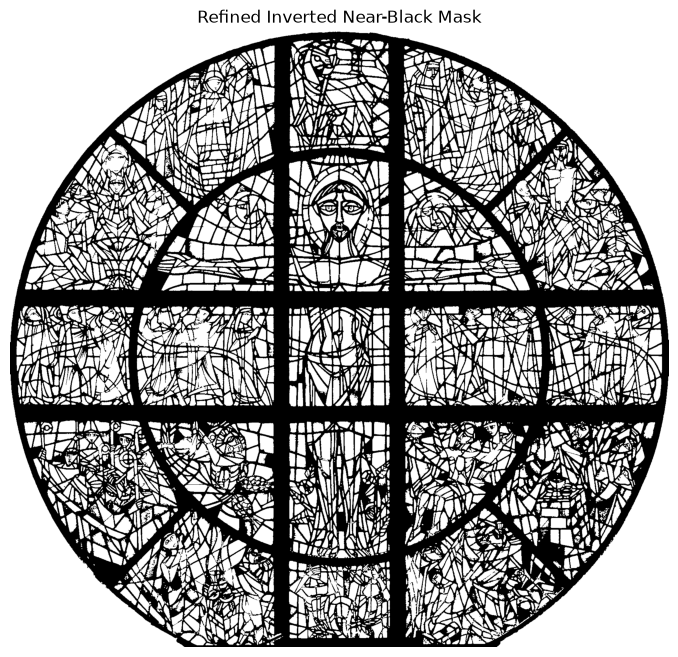

In [3]:
# 5. Refine near-black pixels and invert them into the final binary mask
black_value_threshold = 65
black_chroma_threshold = 35
closing_kernel_size = 3
closing_iterations = 1
minimum_dark_component_area = 12

# Analyze at the final output size so the exported mask matches Processing textures.
if output_scale == 1.0:
    structure_bgr = img_bgr.copy()
    structure_alpha = img_alpha.copy()
else:
    structure_bgr = cv2.resize(img_bgr, output_size, interpolation=cv2.INTER_AREA)
    structure_alpha = cv2.resize(img_alpha, output_size, interpolation=cv2.INTER_NEAREST)

structure_hsv = cv2.cvtColor(structure_bgr, cv2.COLOR_BGR2HSV)
value = structure_hsv[:, :, 2]
channel_chroma = structure_bgr.max(axis=2) - structure_bgr.min(axis=2)
visible_pixels = structure_alpha > 0

# Low value finds dark pixels; low chroma prevents dark saturated glass from becoming frame.
dark_neutral_candidates = (
    (value <= black_value_threshold)
    & (channel_chroma <= black_chroma_threshold)
    & visible_pixels
).astype(np.uint8) * 255

closing_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (closing_kernel_size, closing_kernel_size)
)
closed_dark_candidates = cv2.morphologyEx(
    dark_neutral_candidates,
    cv2.MORPH_CLOSE,
    closing_kernel,
    iterations=closing_iterations
)

# Preserve structural components while discarding isolated dark specks.
component_count, component_labels, component_stats, _ = cv2.connectedComponentsWithStats(
    closed_dark_candidates,
    connectivity=8
)
cleaned_dark_candidates = np.zeros_like(closed_dark_candidates)
for component_label in range(1, component_count):
    component_area = component_stats[component_label, cv2.CC_STAT_AREA]
    if component_area >= minimum_dark_component_area:
        cleaned_dark_candidates[component_labels == component_label] = 255

shape_mask_export = cv2.bitwise_not(cleaned_dark_candidates)
shape_mask_out = os.path.join(output_dir, 'mask_colored_areas.png')
cv2.imwrite(shape_mask_out, shape_mask_export)

unique_values = np.unique(shape_mask_export)
removed_component_count = np.count_nonzero(
    component_stats[1:, cv2.CC_STAT_AREA] < minimum_dark_component_area
)
print(f"Saved refined inverted near-black mask: {shape_mask_out}")
print(f"Output values: {unique_values.tolist()}")
print(f"Tiny dark components removed: {removed_component_count}")

plt.figure(figsize=(12, 8))
plt.imshow(shape_mask_export, cmap='gray', vmin=0, vmax=255)
plt.title('Refined Inverted Near-Black Mask')
plt.axis('off')
plt.show()

Saved Area ID map: Visualizer/data\mask_area_ids.png with 5442 unique areas


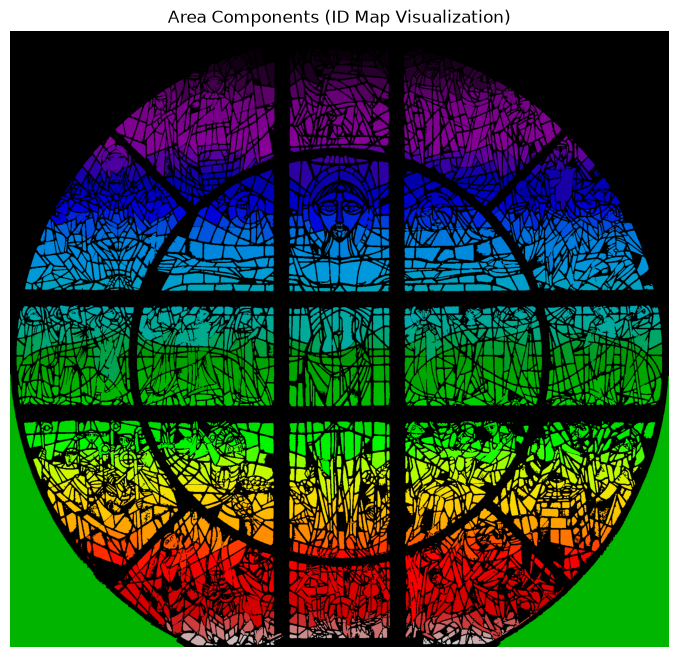

In [5]:
# 6. Generate Area ID Map for dynamic pane lighting
num_labels, labels = cv2.connectedComponents(shape_mask_export, connectivity=4)

# We encode the integer ID into the B, G, R channels so we can save it as a standard PNG
# OpenCV uses BGR ordering for saving. 
id_mask_bgr = np.zeros((labels.shape[0], labels.shape[1], 3), dtype=np.uint8)
id_mask_bgr[:, :, 0] = labels & 0xFF               # Blue channel (lowest 8 bits)
id_mask_bgr[:, :, 1] = (labels >> 8) & 0xFF        # Green channel (middle 8 bits)
id_mask_bgr[:, :, 2] = (labels >> 16) & 0xFF       # Red channel (highest 8 bits)

# Resize to Processing texture size using nearest neighbor so IDs aren't interpolated/corrupted
if output_scale != 1.0:
    id_mask_bgr = cv2.resize(
        id_mask_bgr,
        output_size,
        interpolation=cv2.INTER_NEAREST
    )

id_mask_out = os.path.join(output_dir, 'mask_area_ids.png')
cv2.imwrite(id_mask_out, id_mask_bgr)
print(f"Saved Area ID map: {id_mask_out} with {num_labels} unique areas")

plt.figure(figsize=(12, 8))
# For visualization, just map the raw labels to a random colormap
plt.imshow(cv2.resize(labels, output_size, interpolation=cv2.INTER_NEAREST), cmap='nipy_spectral')
plt.title('Area Components (ID Map Visualization)')
plt.axis('off')
plt.show()